<a href="https://colab.research.google.com/github/Starzyk-P/ml4space/blob/main/ml4space_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [48]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [49]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

Mark how we have used the command $matrix$ to generate a matrix from the image!

If we do not convert the image to grayscale, it will be loaded as a 3D array with three separate color channels (like in RGB). Because standard SVD operates on 2D matrices, the process will calculate three separate SVDs independently for each color layer.

In [50]:
#img = Image.open("/content/drive/My Drive/ML4_Space/NDVI.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/NDBI.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/MNDWI.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/albedo.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/NDMI.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/RGB.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/k_NDVI.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/k_NDBI.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/k_MNDWI.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/k_albedo.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/k_NDMI.tif")
img = Image.open("/content/drive/My Drive/ML4_Space/k_RGB.tif")
#img = Image.open("/content/drive/My Drive/ML4_Space/kk_RGB.tif")
imggray = img.convert('L')

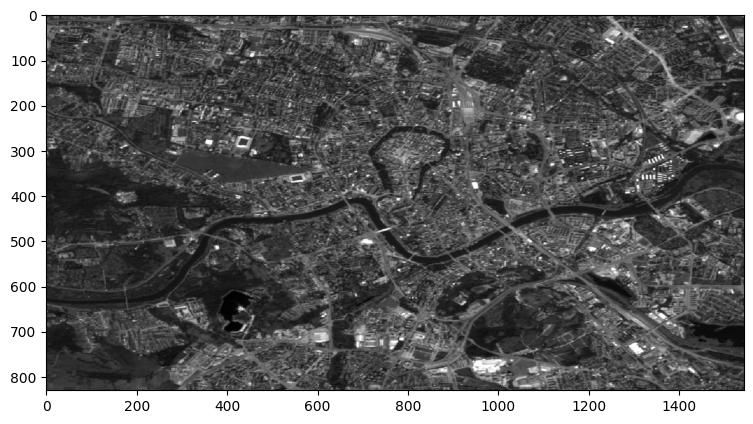

In [51]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

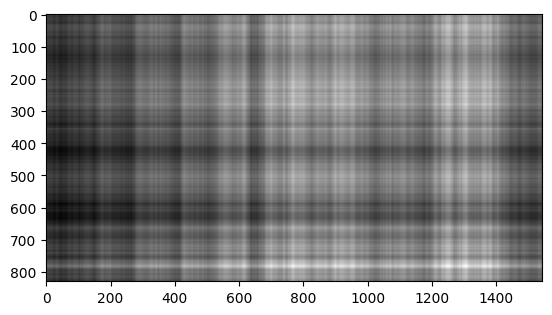

In [52]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?


The plot drops immiediatly and gets flatter after this indicates that vast majority of the image's energy and structural information is concentrated in the very first few vectors.
The first vectors contain the dominant global brightness and contrast, removing them changes the primary structure. The resulting image will be unrecognizble, leaving only high-frequency noise and faint edge details.



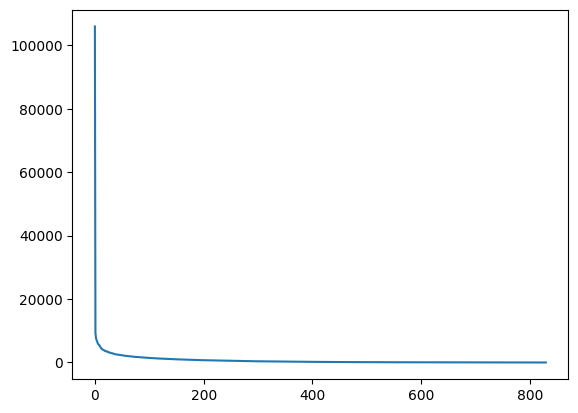

In [53]:
U.shape
sigma.shape
plt.plot(sigma)

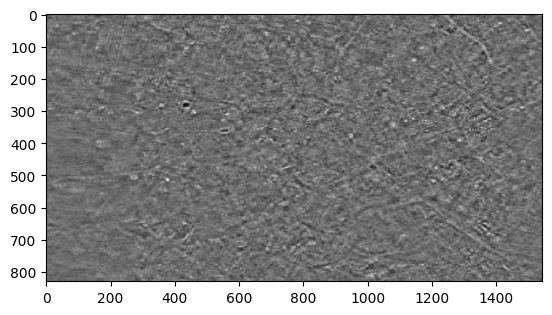

In [54]:
# i = 70
# j = 0
# i = 50
# j = 10
# i = 50
# j = 20
# i = 60
# j = 10
i = 70
j = 20
#i = 150
#j = 100
# i = 30
# j = 10
# i = 80
# j = 40
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

In stead of using the largest $k$ Eigen values, if you use 10th, 11th,,,,k+10 engine values, would you get better images?

Answer: No

Note how many Eigen values are enough to capture the original image without perceptual degradation. Note on your observations.

Answer:
NDBI - These images have a lot of sharp edges, high contrast, and complex textures from buildings and roads. Because of this, we need to use a higher number of eigenvalues 100-150 to capture the image without perceptual degradation.

NDVI - Vegetation areas are relatively more different than cities, but the canopy still provides some texture. Using 40-80 eigenvalues is enough to get a decent reconstruction of the image.

NDMI, MNDWI - Water entities are very flat and similar. Because the surface has almost no spatial variance, the vast majority of the image information is captured in just the first few vectors. We only need 10-30 eigenvalues for a clear image.